# 05 · Robustness: how much should we trust the headline rules?

Notebook 04 found headline features whose effects replicated on held-back data. This notebook asks whether those effects are strong enough to *decide* with, using four sensitivity checks on the same pre-registered features.

> **Status:** post-hoc sensitivity analyses, exploratory by label. They use the exploratory and confirmatory samples. The holdout sample is never touched. The archive has no topic labels, so "by topic" cannot be checked here; time period is used instead.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abtest import data, plotting as P, provenance
from abtest.features import FEATURES, LENGTH, headline_features, pairwise_win_rates, within_test_fit, word_count
from abtest.frequentist import two_proportion_ztest

P.apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RESULTS = {}

arms = {s: data.headline_arms(data.load_packages(s)) for s in ("exploratory", "confirmatory")}
conf = arms["confirmatory"]
print({s: f"{a.test_id.nunique():,} tests / {len(a):,} headlines" for s, a in arms.items()})

{'exploratory': '1,825 tests / 8,354 headlines', 'confirmatory': '8,794 tests / 40,442 headlines'}


## 1 · Does the "better" headline actually win head-to-head?

For every pair of headlines in the same test that differ on a feature, check which one got the higher CTR. For length, the comparison is between headlines at least 3 words apart. 50% is a coin flip. Intervals come from a cluster bootstrap over tests.

In [2]:
wr = {s: pairwise_win_rates(a, n_boot=2000, seed=0) for s, a in arms.items()}
RESULTS["win_rates"] = {s: w.reset_index().to_dict(orient="records") for s, w in wr.items()}
wr["confirmatory"]

,tests,pairs,win_rate,ci_lo,ci_hi
feature,,,,,
number,3096,15152,0.548,0.536,0.560
question,3955,18589,0.428,0.417,0.439
exclamation,705,2815,0.420,0.394,0.447
you / your,4651,22544,0.504,0.494,0.514
I / me / my,2519,11511,0.558,0.544,0.571
this / these / here's,5089,25040,0.556,0.547,0.565
negative word,2316,10689,0.564,0.551,0.578
length (+10 words),7395,35890,0.549,0.541,0.555


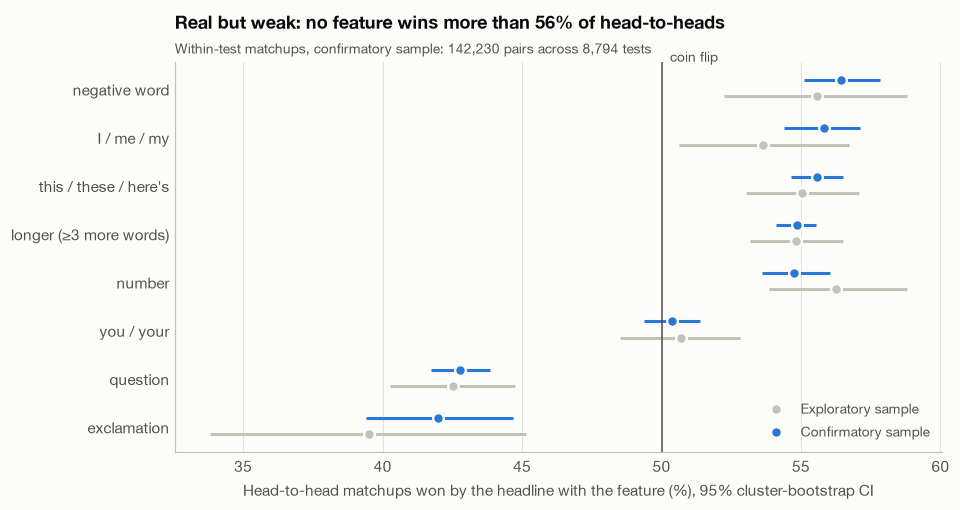

Longer headline wins 54.9% of matchups [54.1%, 55.5%]


In [3]:
order = wr["confirmatory"]["win_rate"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 4.6))
for s, color, off in [("exploratory", P.CONTEXT, -0.17), ("confirmatory", P.BLUE, 0.17)]:
    w = wr[s].loc[order]
    ax.hlines(y + off, w.ci_lo * 100, w.ci_hi * 100, color=color, lw=2)
    ax.plot(w.win_rate * 100, y + off, "o", color=color, ms=7, mec=P.SURFACE, mew=1.5, label=f"{s.title()} sample")
ax.axvline(50, color=P.INK_2, lw=1)
ax.text(50.3, len(order) - 0.45, "coin flip", color=P.INK_2, fontsize=9)
labels = {LENGTH: "longer (≥3 more words)"}
ax.set_yticks(y, [labels.get(f, f) for f in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Head-to-head matchups won by the headline with the feature (%), 95% cluster-bootstrap CI")
ax.legend(loc="lower right")
top = wr["confirmatory"]["win_rate"].max()
ax.set_title(f"Real but weak: no feature wins more than {top:.0%} of head-to-heads")
P.subtitle(ax, f"Within-test matchups, confirmatory sample: {wr['confirmatory']['pairs'].sum():,} pairs across {conf.test_id.nunique():,} tests")
P.save(fig, "15_feature_win_rates")
plt.show()
L = wr["confirmatory"].loc[LENGTH]
print(f"Longer headline wins {L.win_rate:.1%} of matchups [{L.ci_lo:.1%}, {L.ci_hi:.1%}]")

The effects are real, since the confirmatory intervals exclude 50%, but no single feature tells you which headline will win.

## 2 · Is the length effect an artifact of where we draw the line?

Replace continuous length with a binary "long headline" flag at every cut-off from 10 to 20 words, keeping the other seven features in the model.

In [4]:
X = headline_features(conf["headline"]).drop(columns=[LENGTH])
wc = word_count(conf["headline"])
rows = []
for k in range(10, 21):
    out, _ = within_test_fit(conf, X.assign(long=(wc >= k).astype(float)))
    rows.append({"threshold_words": k, "share_long": (wc >= k).mean(), **out.loc["long", ["odds_ratio", "or_lo", "or_hi", "p"]].to_dict()})
sweep = pd.DataFrame(rows)
RESULTS["length_threshold_sweep"] = sweep.to_dict(orient="records")
sweep

,threshold_words,share_long,odds_ratio,or_lo,or_hi,p
0,10,0.951,1.096,1.074,1.118,0.000
1,11,0.914,1.080,1.063,1.097,0.000
2,12,0.862,1.059,1.046,1.073,0.000
3,13,0.791,1.040,1.028,1.052,0.000
4,14,0.704,1.043,1.032,1.054,0.000
5,15,0.598,1.041,1.031,1.052,0.000
6,16,0.476,1.037,1.027,1.047,0.000
7,17,0.344,1.032,1.022,1.042,0.000
8,18,0.221,1.034,1.023,1.045,0.000
9,19,0.119,1.015,1.002,1.028,0.026


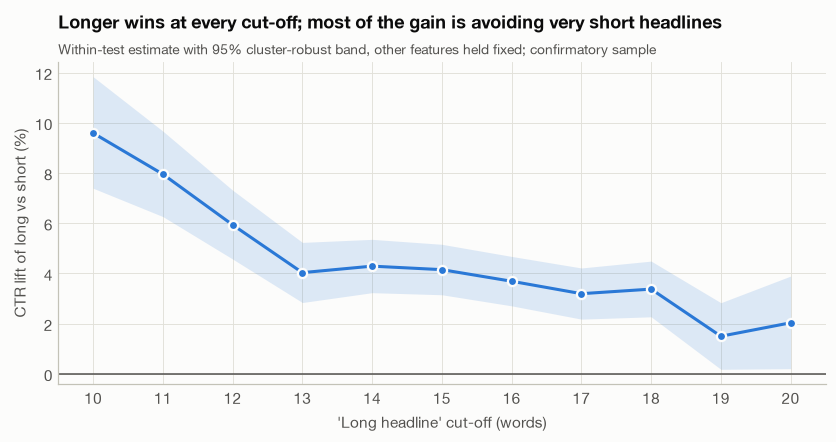

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.fill_between(sweep.threshold_words, (sweep.or_lo - 1) * 100, (sweep.or_hi - 1) * 100, color=P.BLUE, alpha=0.15, lw=0)
ax.plot(sweep.threshold_words, (sweep.odds_ratio - 1) * 100, color=P.BLUE, marker="o", ms=6, mec=P.SURFACE, mew=1.5)
ax.axhline(0, color=P.INK_2, lw=1)
ax.set_xticks(sweep.threshold_words)
ax.set_xlabel("'Long headline' cut-off (words)")
ax.set_ylabel("CTR lift of long vs short (%)")
holds = (sweep.or_lo > 1).all()
ax.set_title("Longer wins at every cut-off; most of the gain is avoiding very short headlines" if holds else "The length effect depends on the cut-off")
P.subtitle(ax, "Within-test estimate with 95% cluster-robust band, other features held fixed; confirmatory sample")
P.save(fig, "16_length_threshold_sensitivity")
plt.show()

## 3 · Are the effects stable over time?

The same within-test model is fitted separately for each year of the confirmatory sample. 2015 covers January to April only.

In [6]:
conf_year = conf["created_at"].dt.year
by_year = {}
for yr in sorted(conf_year.unique()):
    sub = conf[conf_year == yr]
    out, _ = within_test_fit(sub)
    by_year[int(yr)] = out.assign(tests=sub.test_id.nunique())
stable = {f: all(o.loc[f, "or_lo"] > 1 for o in by_year.values()) or all(o.loc[f, "or_hi"] < 1 for o in by_year.values())
          for f in FEATURES}
RESULTS["by_year"] = {yr: o.reset_index(names="feature").to_dict(orient="records") for yr, o in by_year.items()}
RESULTS["stable_every_year"] = stable
pd.DataFrame({yr: o["odds_ratio"] for yr, o in by_year.items()}).assign(stable_every_year=pd.Series(stable))

,2013,2014,2015,stable_every_year
number,1.087,1.062,1.046,True
question,0.917,0.919,0.902,True
exclamation,0.942,0.933,1.011,False
you / your,1.006,1.008,1.006,False
I / me / my,1.004,1.034,1.103,False
this / these / here's,1.058,1.048,1.074,True
negative word,1.023,1.082,1.006,False
length (+10 words),1.081,1.103,1.078,True


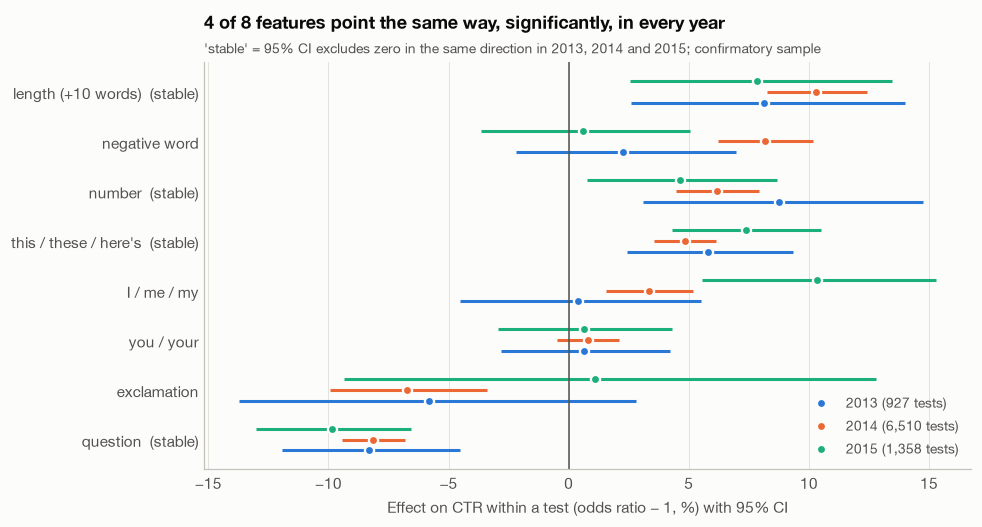

In [7]:
order = by_year[2014]["odds_ratio"].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 4.8))
for (yr, o), color, off in zip(by_year.items(), [P.BLUE, P.ORANGE, P.AQUA], [-0.22, 0, 0.22]):
    o = o.loc[order]
    ax.hlines(y + off, (o.or_lo - 1) * 100, (o.or_hi - 1) * 100, color=color, lw=2)
    ax.plot((o.odds_ratio - 1) * 100, y + off, "o", color=color, ms=6, mec=P.SURFACE, mew=1.5,
            label=f"{yr} ({o.tests.iloc[0]:,} tests)")
ax.axvline(0, color=P.INK_2, lw=1)
ax.set_yticks(y, [f"{f}{'  (stable)' if stable[f] else ''}" for f in order])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect on CTR within a test (odds ratio − 1, %) with 95% CI")
ax.legend(loc="lower right")
n_stable = sum(stable.values())
ax.set_title(f"{n_stable} of {len(FEATURES)} features point the same way, significantly, in every year")
P.subtitle(ax, "'stable' = 95% CI excludes zero in the same direction in 2013, 2014 and 2015; confirmatory sample")
P.save(fig, "17_features_by_year")
plt.show()

## 4 · Where does the rule fail?

For each test whose longest and shortest headlines differ by at least 5 words, compare those two directly. Among the *decisive* matchups (p < 0.001), how often did the shorter headline win?

In [8]:
rows = []
for tid, x in conf.groupby("test_id"):
    w = word_count(x["headline"])
    if w.max() - w.min() < 5:
        continue
    lo, sh = x.loc[w.idxmax()], x.loc[w.idxmin()]
    z, p = two_proportion_ztest(lo.clicks, lo.impressions, sh.clicks, sh.impressions)
    rows.append({"test_id": tid, "z": z, "p": p, "long": lo.headline, "short": sh.headline,
                 "ctr_long": lo.ctr, "ctr_short": sh.ctr, "gap_words": w.max() - w.min()})
duel = pd.DataFrame(rows)
decisive = duel[duel.p < 0.001]
short_wins = decisive[decisive.z < 0]
RESULTS.update(duel_tests=len(duel), duel_longer_wins=(duel.z > 0).mean(), decisive=len(decisive),
               decisive_short_wins=len(short_wins), decisive_short_share=len(short_wins) / len(decisive))
print(f"{len(duel):,} longest-vs-shortest duels: longer headline had the higher CTR in {(duel.z > 0).mean():.0%}")
print(f"{len(decisive)} decisive duels (p < 0.001): the SHORTER headline won {len(short_wins)} ({len(short_wins) / len(decisive):.0%})")

5,100 longest-vs-shortest duels: longer headline had the higher CTR in 57%
527 decisive duels (p < 0.001): the SHORTER headline won 172 (33%)


In [9]:
# One illustration: the decisive duel with the largest margin in favour of the shorter headline.
ex = short_wins.loc[short_wins.z.idxmin()]
pd.DataFrame({"headline": [ex.short, ex.long], "words": [len(ex.short.split()), len(ex.long.split())],
              "CTR": [f"{ex.ctr_short:.2%}", f"{ex.ctr_long:.2%}"]}, index=["shorter (won)", "longer"])

,headline,words,CTR
shorter (won),Some Strange Things Are Happening To Astronaut...,10,3.58%
longer,Advice For Saving The Earth From Some Of The O...,15,0.50%


## Summary

| Question | Answer |
|---|---|
| Do the feature effects replicate? | Yes, as shown in notebook 04 (all six pre-registered features). |
| Are they strong enough to pick a winner? | **No.** The headline with a feature wins only 43–56% of head-to-heads. |
| Is the length effect a threshold artifact? | No. It is positive at every cut-off from 10 to 20 words, and largest for avoiding very short headlines. |
| Is it stable over time? | Length, questions, numbers and "this/these" are stable. Negative words and exclamation marks vary by year. |
| Does the rule ever fail? | Often. In about a third of decisive duels, the shorter headline won. |

**Takeaway:** headline rules shift the average a little, but they do not replace testing each headline.

**Limitations:** no topic labels; observational with respect to features (writers chose them); the sensitivity checks are post-hoc.

In [10]:
with open("../reports/results/05_robustness.json", "w") as f:
    json.dump({**RESULTS, "provenance": provenance.collect(samples=("exploratory", "confirmatory"),
                                                         seeds={"win_rate_bootstrap": 0})}, f, indent=2, default=float)